# 03 — Entraînement du UNet
**Entrées :** `data/patchs_{train,val,test}.npz` et `data/config_patchs.json` (notebook 02), `unet.py` (architecture).

**Ce que fait ce notebook :**
1. Charge les patchs (2021 et 2022) et ajoute de l'augmentation de données (retournements, rotations)
2. Entraîne un UNet sur le GPU du Mac (MPS), avec ou sans perte pondérée par classe selon l'essai choisi
3. Garde le meilleur modèle selon l'IoU moyen sur la validation (avec arrêt anticipé)
4. Évalue le modèle sur le jeu de test (global, puis 2021 et 2022 séparément) : matrice de confusion, IoU, F1, exactitude
5. Sauvegarde le modèle, l'historique et les métriques pour le rapport

**Installation (en plus des notebooks précédents) :**
```bash
pip install torch scipy
```

## 0. Imports et choix du processeur

In [1]:

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from unet import UNet

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")      # GPU Apple
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")
print("Calcul sur :", DEVICE)

Calcul sur : mps


## 1. Paramètres d'entraînement
Ce sont les hyperparamètres à justifier dans le rapport. `EPOQUES_MAX` et `PATIENCE` ont été augmentés (80 → 150, 15 → 25) : dans une première série d'essais, l'essai sans poids progressait encore à l'époque 72 sur 80. Il était donc arrêté par la limite, pas par la convergence. Les hyperparamètres communs sont identiques pour tous les essais ; chaque essai ne change **qu'un seul facteur** par rapport à `unet_base`, pour que la différence de résultats puisse lui être attribuée :

| Essai | Poids de classes | Années d'entraînement | Question posée |
|---|---|---|---|
| `unet_base` | oui | 2021 + 2022 | modèle de référence |
| `unet_sans_poids` | non | 2021 + 2022 | les poids sont-ils responsables de la sur-prédiction de la végétation basse ? |
| `unet_2021_seul` | oui | 2021 | que gagne-t-on à ajouter l'image 2022 étiquetée avec les feux ? |

In [2]:
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
MODELE_DIR = Path("modeles")
FIG_DIR.mkdir(exist_ok=True)
MODELE_DIR.mkdir(exist_ok=True)

BASE = 32             # filtres au 1er niveau du UNet (32 -> ~7,8 millions de paramètres)
BATCH = 16
EPOQUES_MAX = 150     # assez long pour que l'arrêt anticipé décide, pas la limite
LR = 1e-3             # taux d'apprentissage initial
WEIGHT_DECAY = 1e-4
PATIENCE = 25         # arrêt si l'IoU de validation ne progresse plus pendant 25 époques
AUGMENTATION = True
GRAINE = 42

ESSAIS = {
    "unet_base":       {"poids_classes": True,  "annees_entrainement": [2021, 2022]},
    "unet_sans_poids": {"poids_classes": False, "annees_entrainement": [2021, 2022]},
    "unet_2021_seul":  {"poids_classes": True,  "annees_entrainement": [2021]},
}
NOM_ESSAI = "unet_2021_seul"   # choisir l'essai à entraîner

POIDS_CLASSES = ESSAIS[NOM_ESSAI]["poids_classes"]
ANNEES_ENTRAINEMENT = ESSAIS[NOM_ESSAI]["annees_entrainement"]
print(f"Essai {NOM_ESSAI} : poids de classes = {POIDS_CLASSES}, années = {ANNEES_ENTRAINEMENT}")

torch.manual_seed(GRAINE)
np.random.seed(GRAINE)

Essai unet_2021_seul : poids de classes = True, années = [2021]


## 2. Chargement des données
L'entraînement et la validation n'utilisent que les années de l'essai (la validation sert à choisir l'époque : elle doit ressembler à ce que le modèle est censé apprendre). Le **test garde toujours les deux années**, pour que tous les essais soient évalués sur exactement les mêmes pixels.

In [3]:
with open(DATA_DIR / "config_patchs.json") as f:
    CONFIG = json.load(f)

IGNORE = CONFIG["ignore"]
CLASSES = {int(k): v for k, v in CONFIG["classes"].items()}
NOMS = [CLASSES[k]["nom"] for k in sorted(CLASSES)]
N_CLASSES = len(NOMS)
N_BANDES = len(CONFIG["bandes"])
CMAP = ListedColormap([CLASSES[k]["couleur"] for k in sorted(CLASSES)])


def charger(split):
    d = np.load(DATA_DIR / f"patchs_{split}.npz")
    X, Y, annee = d["X"], d["y"], d["annee"]
    if split != "test":
        garder = np.isin(annee, ANNEES_ENTRAINEMENT)
        X, Y, annee = X[garder], Y[garder], annee[garder]
    return X, Y, annee


donnees = {s: charger(s) for s in ["train", "val", "test"]}
for s, (X, Y, annee) in donnees.items():
    detail = ", ".join(f"{a} : {(annee == a).sum()}" for a in np.unique(annee))
    print(f"{s:5s} : X {X.shape}  y {Y.shape}  ({detail})")

train : X (313, 6, 256, 256)  y (313, 256, 256)  (2021 : 313)
val   : X (100, 6, 256, 256)  y (100, 256, 256)  (2021 : 100)
test  : X (213, 6, 256, 256)  y (213, 256, 256)  (2021 : 105, 2022 : 108)


## 3. Jeu de données et augmentation
L'augmentation crée des variantes de chaque patch à chaque époque (retournements, rotations de 90°). Une image satellite n'a pas de « haut » ni de « bas » : ces transformations sont donc réalistes, et elles limitent le surapprentissage sur un petit jeu de données.

In [4]:
class Patchs(Dataset):
    def __init__(self, X, Y, augmenter=False):
        self.X, self.Y, self.augmenter = X, Y, augmenter

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        x = self.X[i].astype(np.float32)     # (bandes, H, W)
        y = self.Y[i].astype(np.int64)       # (H, W)
        if self.augmenter:
            k = np.random.randint(4)
            x, y = np.rot90(x, k, axes=(1, 2)), np.rot90(y, k)
            if np.random.rand() < 0.5:
                x, y = x[:, :, ::-1], y[:, ::-1]
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(np.ascontiguousarray(y))


def chargeur(X, Y, augmenter=False, melanger=False):
    # num_workers=0 : évite les blocages de DataLoader dans les notebooks sur macOS
    return DataLoader(Patchs(X, Y, augmenter), batch_size=BATCH, shuffle=melanger, num_workers=0)


chargeurs = {
    "train": chargeur(*donnees["train"][:2], augmenter=AUGMENTATION, melanger=True),
    "val":   chargeur(*donnees["val"][:2]),
    "test":  chargeur(*donnees["test"][:2]),
}
# Test par année : le modèle reconnaît-il aussi bien l'occupation du sol avant et après les feux ?
X_te, Y_te, annee_te = donnees["test"]
chargeurs_test_annee = {int(a): chargeur(X_te[annee_te == a], Y_te[annee_te == a]) for a in np.unique(annee_te)}

## 4. Métriques
Tout part de la **matrice de confusion** (lignes = vraie classe, colonnes = classe prédite). On en déduit :
- **Exactitude globale** : part des pixels bien classés (trompeuse si une classe domine, ici la forêt).
- **IoU** par classe = intersection / union entre prédiction et vérité. Métrique de référence en segmentation.
- **F1** par classe : moyenne harmonique de la précision et du rappel.
- **mIoU** : moyenne des IoU sur les classes présentes.

In [5]:
def matrice_confusion(pred, cible, n=N_CLASSES):
    masque = cible != IGNORE
    return np.bincount(n * cible[masque] + pred[masque], minlength=n * n).reshape(n, n)


def metriques(cm):
    tp = np.diag(cm).astype(float)
    vrais, predits = cm.sum(1).astype(float), cm.sum(0).astype(float)
    present = vrais > 0
    with np.errstate(divide="ignore", invalid="ignore"):
        iou = np.where(present, tp / (vrais + predits - tp), np.nan)
        f1 = np.where(present, 2 * tp / (vrais + predits), np.nan)
        precision = np.where(predits > 0, tp / predits, np.nan)
        rappel = np.where(present, tp / vrais, np.nan)
    return {
        "exactitude": tp.sum() / cm.sum(),
        "miou": np.nanmean(iou),
        "iou": iou, "f1": f1, "precision": precision, "rappel": rappel,
    }

## 5. Modèle, perte et optimiseur
**Poids de classes.** Avec des classes déséquilibrées, l'entropie croisée simple pousse le modèle vers les classes fréquentes (ici la forêt). Les poids (inverse de la racine de la fréquence, calculés sur l'entraînement de l'essai) donnent plus d'importance aux classes rares. Contrepartie : le modèle a tendance à **sur-prédire** les classes rares, ce qui fait baisser leur précision. L'essai `unet_sans_poids` mesure cet effet.

In [6]:
modele = UNet(in_ch=N_BANDES, n_classes=N_CLASSES, base=BASE).to(DEVICE)
n_params = sum(p.numel() for p in modele.parameters())
print(f"UNet : {n_params / 1e6:.1f} millions de paramètres")

# Poids recalculés sur l'entraînement réellement utilisé (même formule que le notebook 02)
Y_tr = donnees["train"][1]
freq = np.bincount(Y_tr[Y_tr != IGNORE], minlength=N_CLASSES).astype(float)
freq /= freq.sum()
poids_np = np.where(freq > 0, 1 / np.sqrt(np.maximum(freq, 1e-12)), 0.0)
poids_np = poids_np / poids_np[freq > 0].mean()
if not POIDS_CLASSES:
    poids_np = np.ones(N_CLASSES)
for k in range(N_CLASSES):
    print(f"  {NOMS[k]:22s} fréquence {freq[k]*100:6.2f} %   poids {poids_np[k]:.2f}")

# Les pixels IGNORE sont exclus de la perte
poids = torch.tensor(poids_np, dtype=torch.float32, device=DEVICE)
perte_fn = nn.CrossEntropyLoss(weight=poids, ignore_index=IGNORE)

optimiseur = torch.optim.AdamW(modele.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
planificateur = torch.optim.lr_scheduler.CosineAnnealingLR(optimiseur, T_max=EPOQUES_MAX)

UNet : 7.8 millions de paramètres
  Forêt                  fréquence  61.03 %   poids 0.24
  Végétation basse       fréquence  21.71 %   poids 0.39
  Cultures               fréquence   7.90 %   poids 0.65
  Bâti                   fréquence   2.97 %   poids 1.07
  Sol nu / brûlé         fréquence   0.40 %   poids 2.90
  Eau / zones humides    fréquence   5.99 %   poids 0.75


## 6. Boucle d'entraînement

In [7]:
def evaluer(chargeur):
    modele.eval()
    cm = np.zeros((N_CLASSES, N_CLASSES), dtype=np.int64)
    perte_tot, n = 0.0, 0
    with torch.no_grad():
        for x, y in chargeur:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = modele(x)
            perte_tot += perte_fn(logits, y).item() * len(x)
            n += len(x)
            pred = logits.argmax(1).cpu().numpy().ravel()
            cm += matrice_confusion(pred, y.cpu().numpy().ravel())
    return perte_tot / n, cm


historique = []
meilleur_miou, sans_progres = -1.0, 0
chemin_modele = MODELE_DIR / f"{NOM_ESSAI}.pt"
debut = time.time()

for epoque in range(1, EPOQUES_MAX + 1):
    t0 = time.time()
    modele.train()
    perte_tot, n = 0.0, 0
    for x, y in chargeurs["train"]:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimiseur.zero_grad()
        perte = perte_fn(modele(x), y)
        perte.backward()
        optimiseur.step()
        perte_tot += perte.item() * len(x)
        n += len(x)
    planificateur.step()

    perte_val, cm_val = evaluer(chargeurs["val"])
    m = metriques(cm_val)
    historique.append({"epoque": epoque, "perte_train": perte_tot / n, "perte_val": perte_val,
                       "miou_val": m["miou"], "exactitude_val": m["exactitude"],
                       "lr": optimiseur.param_groups[0]["lr"]})

    marque = ""
    if m["miou"] > meilleur_miou:
        meilleur_miou, sans_progres = m["miou"], 0
        torch.save({"etat": modele.state_dict(), "base": BASE, "n_bandes": N_BANDES,
                    "n_classes": N_CLASSES, "epoque": epoque}, chemin_modele)
        marque = "  * meilleur"
    else:
        sans_progres += 1

    print(f"Époque {epoque:3d} | perte train {perte_tot / n:.3f} | perte val {perte_val:.3f} | "
          f"mIoU val {m['miou']:.3f} | {time.time() - t0:.1f} s{marque}")

    if sans_progres >= PATIENCE:
        print(f"Arrêt anticipé : pas de progrès depuis {PATIENCE} époques")
        break

duree = time.time() - debut
print(f"\nDurée totale : {duree / 60:.1f} min — meilleur mIoU validation : {meilleur_miou:.3f}")
historique = pd.DataFrame(historique)
historique.to_csv(MODELE_DIR / f"{NOM_ESSAI}_historique.csv", index=False)

Époque   1 | perte train 1.236 | perte val 1.439 | mIoU val 0.474 | 4.4 s  * meilleur


Époque   2 | perte train 0.905 | perte val 0.712 | mIoU val 0.670 | 4.1 s  * meilleur


Époque   3 | perte train 0.749 | perte val 0.675 | mIoU val 0.657 | 4.0 s


Époque   4 | perte train 0.646 | perte val 0.534 | mIoU val 0.711 | 4.0 s  * meilleur


Époque   5 | perte train 0.580 | perte val 0.469 | mIoU val 0.712 | 4.0 s  * meilleur


Époque   6 | perte train 0.516 | perte val 0.498 | mIoU val 0.705 | 4.0 s


... (60 outputs left out)

Époque  67 | perte train 0.282 | perte val 0.256 | mIoU val 0.755 | 4.1 s


Époque  68 | perte train 0.283 | perte val 0.255 | mIoU val 0.775 | 4.1 s


Époque  69 | perte train 0.284 | perte val 0.253 | mIoU val 0.771 | 4.1 s


Époque  70 | perte train 0.283 | perte val 0.264 | mIoU val 0.763 | 4.1 s
Arrêt anticipé : pas de progrès depuis 25 époques

Durée totale : 4.7 min — meilleur mIoU validation : 0.779


## 7. Courbes d'apprentissage
Si la perte de validation remonte alors que celle d'entraînement continue de baisser, le modèle **surapprend**. L'arrêt anticipé et la sauvegarde du meilleur modèle limitent ce problème.

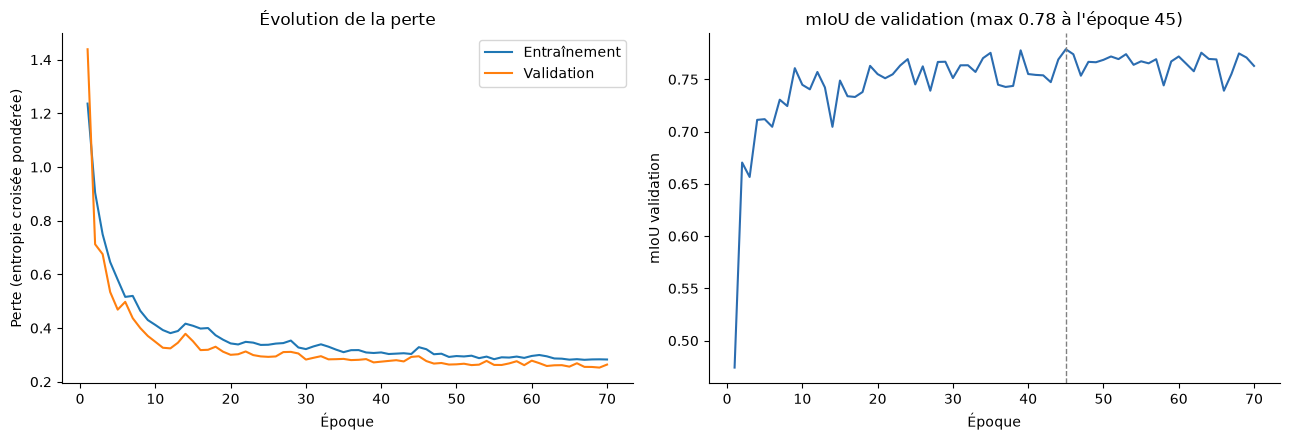

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(historique["epoque"], historique["perte_train"], label="Entraînement")
axes[0].plot(historique["epoque"], historique["perte_val"], label="Validation")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Perte (entropie croisée" + (" pondérée)" if POIDS_CLASSES else ")"))
axes[0].set_title("Évolution de la perte"); axes[0].legend()

axes[1].plot(historique["epoque"], historique["miou_val"], color="#2b6cb0")
meilleure = historique.loc[historique["miou_val"].idxmax()]
axes[1].axvline(meilleure["epoque"], ls="--", color="grey", lw=1)
axes[1].set_xlabel("Époque"); axes[1].set_ylabel("mIoU validation")
axes[1].set_title(f"mIoU de validation (max {meilleure['miou_val']:.2f} à l'époque {int(meilleure['epoque'])})")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / f"courbes_{NOM_ESSAI}.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Évaluation sur le jeu de test
On recharge le **meilleur** modèle (pas le dernier) et on l'évalue sur des patchs qu'il n'a jamais vus, ni pendant l'entraînement ni pour choisir l'époque.

In [9]:
point = torch.load(chemin_modele, map_location=DEVICE)
modele.load_state_dict(point["etat"])
print(f"Meilleur modèle : époque {point['epoque']}")


def tableau_metriques(cm):
    m = metriques(cm)
    t = pd.DataFrame({
        "classe": NOMS,
        "pixels_test": cm.sum(1),
        "IoU": m["iou"], "F1": m["f1"],
        "précision": m["precision"], "rappel": m["rappel"],
    }).round(3)
    return m, t


_, cm_test = evaluer(chargeurs["test"])
m_test, tableau = tableau_metriques(cm_test)
print(f"Test, toutes années : exactitude {m_test['exactitude']:.3f}   mIoU {m_test['miou']:.3f}")
display(tableau)

par_annee = {}
for a, ch in chargeurs_test_annee.items():
    _, cm_a = evaluer(ch)
    m_a, t_a = tableau_metriques(cm_a)
    par_annee[a] = {"exactitude": float(m_a["exactitude"]), "miou": float(m_a["miou"]),
                    "par_classe": t_a.to_dict(orient="records"), "matrice_confusion": cm_a.tolist()}
    print(f"\nTest {a} : exactitude {m_a['exactitude']:.3f}   mIoU {m_a['miou']:.3f}")
    display(t_a)

Meilleur modèle : époque 45


Test, toutes années : exactitude 0.822   mIoU 0.571


,classe,pixels_test,IoU,F1,précision,rappel
0,Forêt,7229571,0.830,0.907,0.891,0.924
1,Végétation basse,2792040,0.540,0.701,0.697,0.705
2,Cultures,1471086,0.603,0.752,0.721,0.787
3,Bâti,384133,0.611,0.758,0.671,0.872
4,Sol nu / brûlé,631470,0.008,0.015,0.442,0.008
5,Eau / zones humides,1235197,0.836,0.910,0.886,0.936



Test 2021 : exactitude 0.890   mIoU 0.678


,classe,pixels_test,IoU,F1,précision,rappel
0,Forêt,3873169,0.883,0.938,0.932,0.944
1,Végétation basse,1464453,0.615,0.761,0.783,0.741
2,Cultures,737471,0.763,0.866,0.850,0.882
3,Bâti,185446,0.645,0.784,0.725,0.853
4,Sol nu / brûlé,6663,0.235,0.380,0.514,0.302
5,Eau / zones humides,542794,0.925,0.961,0.991,0.933



Test 2022 : exactitude 0.756   mIoU 0.514


,classe,pixels_test,IoU,F1,précision,rappel
0,Forêt,3356402,0.774,0.873,0.847,0.901
1,Végétation basse,1327587,0.470,0.639,0.614,0.666
2,Cultures,733615,0.475,0.644,0.603,0.691
3,Bâti,198687,0.583,0.737,0.628,0.890
4,Sol nu / brûlé,624807,0.004,0.009,0.401,0.004
5,Eau / zones humides,692403,0.777,0.875,0.818,0.939


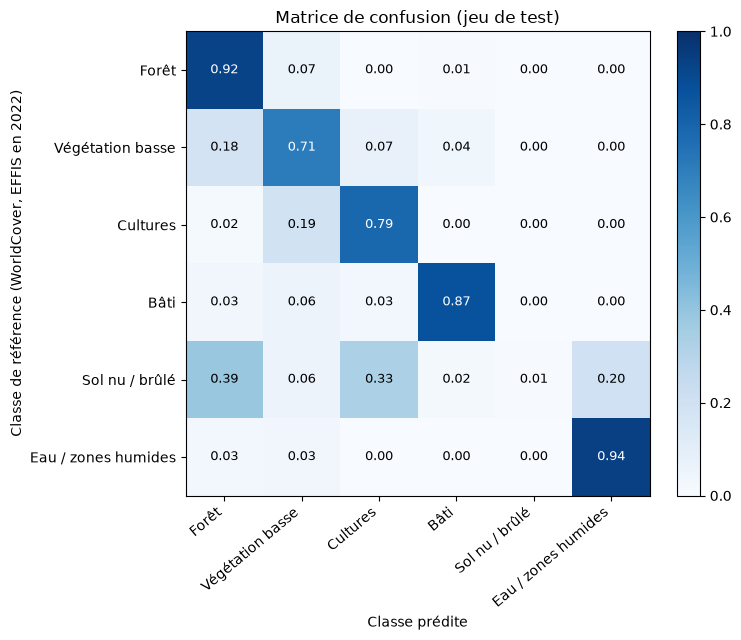

In [10]:
# Matrice de confusion normalisée par ligne (part de chaque vraie classe)
with np.errstate(invalid="ignore"):
    cm_norm = cm_test / cm_test.sum(1, keepdims=True)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(N_CLASSES), NOMS, rotation=40, ha="right")
ax.set_yticks(range(N_CLASSES), NOMS)
ax.set_xlabel("Classe prédite"); ax.set_ylabel("Classe de référence (WorldCover, EFFIS en 2022)")
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if not np.isnan(cm_norm[i, j]):
            ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=9)
ax.set_title("Matrice de confusion (jeu de test)")
plt.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.savefig(FIG_DIR / f"confusion_{NOM_ESSAI}.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Exemples de prédictions

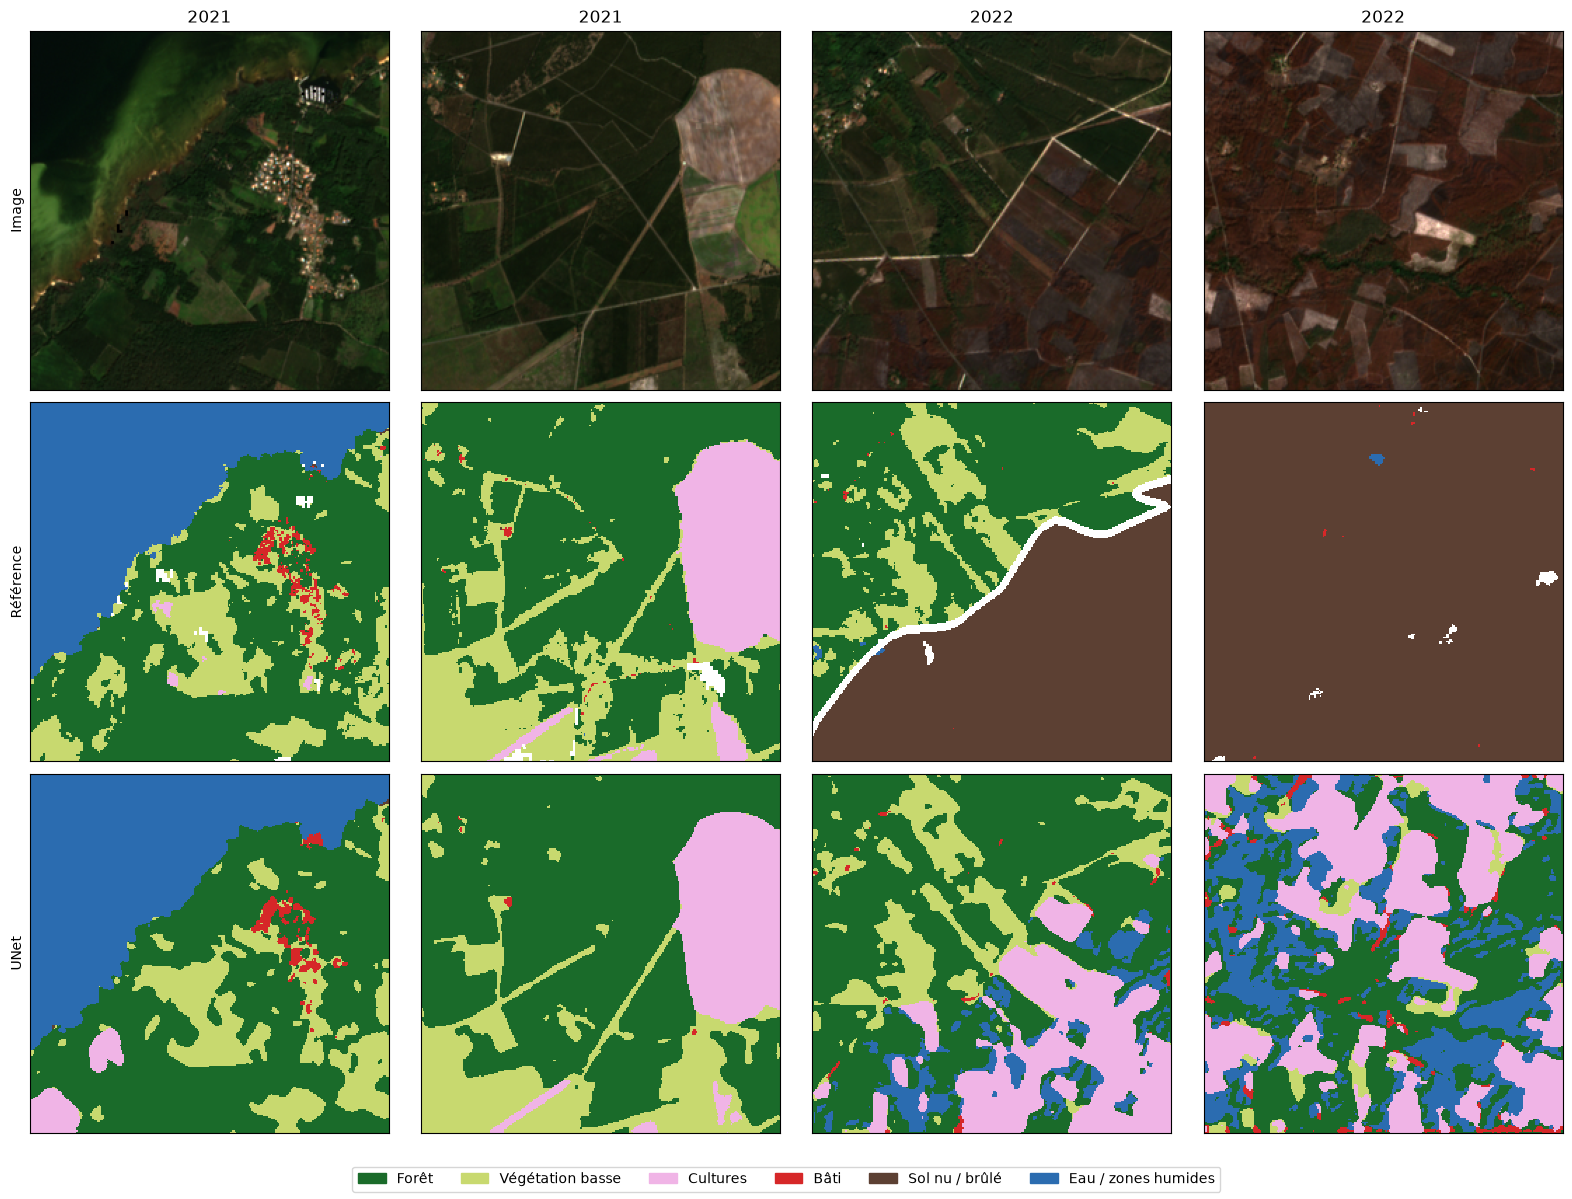

In [11]:
moy = np.array(CONFIG["moyenne"])[:, None, None]
ect = np.array(CONFIG["ecart_type"])[:, None, None]
rng = np.random.default_rng(1)
# 2 patchs de test 2021 et 2 patchs de test 2022 (de préférence touchés par les feux)
brule_te = (Y_te == CONFIG["classe_brulee"]).mean(axis=(1, 2))
candidats_2022 = np.flatnonzero((annee_te == 2022) & (brule_te > 0.10))
if len(candidats_2022) < 2:
    candidats_2022 = np.flatnonzero(annee_te == 2022)
idx = np.concatenate([
    rng.choice(np.flatnonzero(annee_te == 2021), size=2, replace=False),
    rng.choice(candidats_2022, size=min(2, len(candidats_2022)), replace=False),
])

modele.eval()
with torch.no_grad():
    preds = modele(torch.from_numpy(X_te[idx].astype(np.float32)).to(DEVICE)).argmax(1).cpu().numpy()

fig, axes = plt.subplots(3, len(idx), figsize=(4 * len(idx), 12), squeeze=False)
for c, k in enumerate(idx):
    refl = X_te[k].astype(np.float32) * ect + moy            # retour aux réflectances
    rgb = np.clip(np.stack([refl[2], refl[1], refl[0]], -1) / 0.25, 0, 1)
    axes[0, c].imshow(rgb)
    axes[0, c].set_title(str(annee_te[k]))
    axes[1, c].imshow(np.ma.masked_equal(Y_te[k], IGNORE), cmap=CMAP, vmin=0, vmax=N_CLASSES - 1, interpolation="nearest")
    axes[2, c].imshow(preds[c], cmap=CMAP, vmin=0, vmax=N_CLASSES - 1, interpolation="nearest")
axes[0, 0].set_ylabel("Image"); axes[1, 0].set_ylabel("Référence"); axes[2, 0].set_ylabel("UNet")
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
handles = [plt.Rectangle((0, 0), 1, 1, color=CLASSES[k]["couleur"]) for k in range(N_CLASSES)]
fig.legend(handles, NOMS, loc="lower center", ncol=N_CLASSES)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig(FIG_DIR / f"exemples_predictions_{NOM_ESSAI}.png", dpi=200, bbox_inches="tight")
plt.show()

## 10. Sauvegarde des résultats de l'essai

In [12]:
resultats = {
    "essai": NOM_ESSAI,
    "hyperparametres": {"poids_classes": POIDS_CLASSES, "annees": "+".join(map(str, ANNEES_ENTRAINEMENT)),
                        "base": BASE, "batch": BATCH, "lr": LR, "weight_decay": WEIGHT_DECAY,
                        "epoques_max": EPOQUES_MAX, "patience": PATIENCE, "augmentation": AUGMENTATION},
    "poids_utilises": poids_np.tolist(),
    "n_parametres": n_params,
    "meilleure_epoque": int(point["epoque"]),
    "miou_val": float(meilleur_miou),
    "duree_min": round(duree / 60, 1),
    "test": {"exactitude": float(m_test["exactitude"]), "miou": float(m_test["miou"]),
             "par_classe": tableau.to_dict(orient="records")},
    "test_par_annee": par_annee,
    "matrice_confusion_test": cm_test.tolist(),
}
with open(MODELE_DIR / f"{NOM_ESSAI}_resultats.json", "w") as f:
    json.dump(resultats, f, indent=2, ensure_ascii=False, default=float)
print(f"-> {MODELE_DIR / (NOM_ESSAI + '_resultats.json')}")

-> modeles/unet_2021_seul_resultats.json


## Comparer plusieurs essais
Relance le notebook en changeant `NOM_ESSAI` (un seul facteur change à chaque fois, voir le tableau de la section 1), puis exécute les cellules ci-dessous pour obtenir les tableaux comparatifs pour le rapport.

Pour **choisir** le modèle utilisé ensuite, on regarde le mIoU de **validation**, pas celui du test : choisir sur le test reviendrait à l'utiliser pour régler le modèle, et il ne serait plus une estimation honnête.

In [13]:
lignes = []
for f in sorted(MODELE_DIR.glob("*_resultats.json")):
    r = json.load(open(f))
    ligne = {"essai": r["essai"], "poids": r["hyperparametres"].get("poids_classes"),
             "années": r["hyperparametres"].get("annees"),
             "époque": r["meilleure_epoque"], "durée (min)": r["duree_min"],
             "mIoU val": round(r.get("miou_val", float("nan")), 3),
             "exactitude test": round(r["test"]["exactitude"], 3),
             "mIoU test": round(r["test"]["miou"], 3)}
    for a, ra in r.get("test_par_annee", {}).items():
        ligne[f"mIoU test {a}"] = round(ra["miou"], 3)
    lignes.append(ligne)
display(pd.DataFrame(lignes))

# IoU et précision par classe, test toutes années
lignes = []
for f in sorted(MODELE_DIR.glob("*_resultats.json")):
    r = json.load(open(f))
    for c in r["test"]["par_classe"]:
        lignes.append({"essai": r["essai"], "classe": c["classe"], "IoU": c["IoU"], "précision": c["précision"], "rappel": c["rappel"]})
pd.DataFrame(lignes).pivot(index="classe", columns="essai", values=["IoU", "précision", "rappel"]).loc[NOMS].round(3)

,essai,poids,années,époque,durée (min),mIoU val,exactitude test,mIoU test,mIoU test 2021,mIoU test 2022
0,unet_2021_seul,True,2021,45,4.7,0.779,0.822,0.571,0.678,0.514
1,unet_base,True,2021+2022,126,20.1,0.797,0.886,0.788,0.680,0.778
2,unet_sans_poids,False,2021+2022,117,19.1,0.803,0.891,0.793,0.684,0.787


IoU                                précision  \
essai               unet_2021_seul unet_base unet_sans_poids unet_2021_seul   
classe                                                                        
Forêt                        0.830     0.870           0.877          0.891   
Végétation basse             0.540     0.607           0.618          0.697   
Cultures                     0.603     0.754           0.751          0.721   
Bâti                         0.611     0.626           0.643          0.671   
Sol nu / brûlé               0.008     0.933           0.939          0.442   
Eau / zones humides          0.836     0.936           0.931          0.886   

                                                      rappel            \
essai               unet_base unet_sans_poids unet_2021_seul unet_base   
classe                                                                   
Forêt                   0.951           0.930          0.924     0.911   
Végétation basse        0.739           0.756          0.705     0.773   
Cultures                0.835           0.893          0.787     0.886   
Bâti                    0.672           0.747          0.872     0.900   
Sol nu / brûlé          0.959           0.968          0.008     0.971   
Eau / zones humides     0.987           0.992          0.936     0.948   

                                     
essai               unet_sans_poids  
classe                               
Forêt                         0.940  
Végétation basse              0.773  
Cultures                      0.825  
Bâti                          0.822  
Sol nu / brûlé                0.969  
Eau / zones humides           0.938

## Notes pour le rapport
- *Methods* : architecture (UNet, 4 niveaux, nombre de paramètres), perte (pondérée ou non), optimiseur AdamW + décroissance cosinus, augmentation, arrêt anticipé, choix du modèle sur la validation, plan d'expériences (un facteur à la fois).
- *Results* : tableau IoU/F1 par classe (global et par année), matrice de confusion, courbes d'apprentissage, comparaison des essais.
- *Discussion* : quelles classes sont confondues et pourquoi (végétation basse / cultures ? sol nu / bâti ? brûlé / eau ?). Effet des poids sur la précision de la végétation basse. Rappeler que la « vérité » est WorldCover (et EFFIS pour 2022), elles-mêmes imparfaites.